# CNN Model Development - NIH Chest X-ray Classification

### Objective

This notebook develops a simple Convolutional Neural Network (CNN) using PyTorch to classify chest X-ray images into two categories: Effusion and No Finding.

### Execution Plan

In this notebook, we will
1. Load existing dataset and construct PyTorch DataLoaders
2. Build CNN architecture
3. Inspect model parameters and tensor dimensions
4. Train CNN using native PyTorch training loop
5. Evaluate model performance on validation and test sets
6. Compare CNN against MLP
7. Experiment with image augmentation and assess its impact on model performance

### Learning Focus

Understand how convolutional layers, feature maps, pooling, and fully connected layers work together to extract image features and perform classification. 

### Limitations

This is an educational project and is not intended for clinical diagnosis.

## 01. Dataset

NIH ChestX-ray14 subset of 3241 images, will be split following the MLP model for consistency and to allow for comparisons between the 2 models.

In [61]:
import torch
import pandas as pd
import numpy as np
import random

# Load preprocessed tensors
data = torch.load(
    "../../data/processed/mlp_images_64x64.pt",
    map_location="cpu",
    weights_only=True)

X = data["X"]
y = data["y"]
image_names = data["image_names"]
patient_ids = data["patient_ids"]  
splits = data["splits"]  

print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of patients:", len(patient_ids))
print("Number of splits:", len(splits))
print("Data type:", X.dtype)
print("Minimum:", X.min().item())
print("Maximum:", X.max().item())

# Load dataset metadata
df = pd.read_csv("../../data/processed/mlp_dataset.csv")
print("Columns:", df.columns.tolist())
print(f"Split distribution: {df.groupby(['Split', 'Label']).size()}")


Images: torch.Size([3241, 1, 64, 64])
Labels: torch.Size([3241])
Number of patients: 3241
Number of splits: 3241
Data type: torch.float32
Minimum: 0.0
Maximum: 1.0
Columns: ['Image Index', 'Patient ID', 'Label', 'Split']
Split distribution: Split  Label
test   0         329
       1         150
train  0        1939
       1         269
val    0         486
       1          68
dtype: int64


In [62]:
# Add random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 02. Data Preparation

We will confirm that data for CNN model development is identical to the data used for MLP model development:
- 3241 images, with matching tensor and CSV 
- 2208 training, 554 validation, and 479 test images
- Labels encoded as 0 and 1
- Original patient-level splits preserved
- No need to preprocess or split data again

In [15]:
from collections import Counter

# Inspect split and label values
print("Split values:", Counter(splits))
print("Label values:", Counter(y.tolist()))

print("First 5 image names:", image_names[:5])
print("First 5 patient IDs:", patient_ids[:5])

# Verify CSV metadata
print("CSV columns:", df.columns.tolist())
print("Split and label distribution:")
print(df.groupby(["Split", "Label"]).size())
print("First 5 rows:")
display(df.head())

# Check tensor and CSV ordering match
print("Tensor images:", len(X))
print("CSV rows:", len(df))

print("Image names match:",
      image_names == df["Image Index"].tolist())

Split values: Counter({'train': 2208, 'val': 554, 'test': 479})
Label values: Counter({0: 2754, 1: 487})
First 5 image names: ['00000002_000.png', '00000005_000.png', '00000005_001.png', '00000005_002.png', '00000005_003.png']
First 5 patient IDs: [2, 5, 5, 5, 5]
CSV columns: ['Image Index', 'Patient ID', 'Label', 'Split']
Split and label distribution:
Split  Label
test   0         329
       1         150
train  0        1939
       1         269
val    0         486
       1          68
dtype: int64
First 5 rows:


,Image Index,Patient ID,Label,Split
0,00000002_000.png,2,0,train
1,00000005_000.png,5,0,train
2,00000005_001.png,5,0,train
3,00000005_002.png,5,0,train
4,00000005_003.png,5,0,train


Tensor images: 3241
CSV rows: 3241
Image names match: True


## 03. Model Architecture

### 3.1 Creating PyTorch Datasets and DataLoaders

Datasets store and provide access to individual sample and their labels.
DataLoader retrieves samples from the Dataset and groups them into batches. Training will be performed on these manageable subsets of data.

In [17]:
from torch.utils.data import TensorDataset, DataLoader, Subset

# Create a dataset containing images and labels
dataset = TensorDataset(X, y)

# Get indices for each split
train_idx = [i for i, s in enumerate(splits) if s == "train"]
val_idx = [i for i, s in enumerate(splits) if s == "val"]
test_idx = [i for i, s in enumerate(splits) if s == "test"]

# Create separate datasets
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect 1 batch
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Labels in batch:", labels.unique())

Training batches: 69
Validation batches: 18
Test batches: 15
Image batch shape: torch.Size([32, 1, 64, 64])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Labels in batch: tensor([0, 1])


There are 69 training batches, 18 validation batches, and 15 test batches of 32 images each. 

Each image has 1 channel (grayscale), 64 pixels in height and 64 pixels in width (64x64), with the labels containing corresponding diagnosis class for each image.

### 3.2 Building the CNN Architecture

1. First convolution layer (nn.Conv2d)
2. ReLU activation to introduce non-linearity
3. MaxPooling (nn.MaxPool)
4. Second convolution layer (nn.Conv2d)
5. ReLU activation
6. MaxPooling
7. nn.Flatten
8. nn.Linear

In [34]:
import torch.nn as nn

# CNN Model
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(8192, 2)) #(32*16*16)

## 04. Training CNN model

### 4.1 Configure Loss Function, Optimizer, and Device

In [35]:
import torch.optim as optim

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
model = model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: cpu


### 4.2 Training Loop for 10 epochs

In [36]:
import copy 

NUM_EPOCHS = 10
cnn_train_losses = []
cnn_val_losses = []
best_val_loss = float("inf")
best_model_state = None

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    epoch_train_loss = running_train_loss / len(train_loader)
    cnn_train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()
    epoch_val_loss = running_val_loss / len(val_loader)
    cnn_val_losses.append(epoch_val_loss)

    # Best model with least loss
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

# Restore best model
model.load_state_dict(best_model_state)

Epoch [1/10] Train Loss: 0.3771 Val Loss: 0.3964
Epoch [2/10] Train Loss: 0.3447 Val Loss: 0.3403
Epoch [3/10] Train Loss: 0.3358 Val Loss: 0.3323
Epoch [4/10] Train Loss: 0.3280 Val Loss: 0.3346
Epoch [5/10] Train Loss: 0.3171 Val Loss: 0.3261
Epoch [6/10] Train Loss: 0.3220 Val Loss: 0.3325
Epoch [7/10] Train Loss: 0.3144 Val Loss: 0.3322
Epoch [8/10] Train Loss: 0.3005 Val Loss: 0.3391
Epoch [9/10] Train Loss: 0.2983 Val Loss: 0.3328
Epoch [10/10] Train Loss: 0.2919 Val Loss: 0.3424
Best epoch: 5
Best validation loss: 0.3261


<All keys matched successfully>

Validation loss reaches its lowest point at epoch 5 (0.3261), then deteoriates while training loss decreases continually. This is an early sign of overfitting. 

Hence, we have saved and restored the best model (epoch 5), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this model on the validation dataset.

## 05. Evaluate CNN Model

Evaluate validation predictions

In [40]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# Switch model to evaluation mode
model.eval()

cnn_predictions = []
cnn_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        cnn_predictions.extend(predictions.cpu().numpy())
        cnn_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(cnn_labels, cnn_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(cnn_labels, cnn_predictions)
classification_metrics = classification_report(cnn_labels, cnn_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
precision = precision_score(cnn_labels, cnn_predictions, zero_division=0)
recall = recall_score(cnn_labels, cnn_predictions, zero_division=0)
f1 = f1_score(cnn_labels, cnn_predictions, zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[471  15]
 [ 59   9]]
Accuracy: 0.8664
Precision: 0.3750
Recall: 0.1324
F1 score: 0.1957
Classification Report:               precision    recall  f1-score   support

  No Finding       0.89      0.97      0.93       486
    Effusion       0.38      0.13      0.20        68

    accuracy                           0.87       554
   macro avg       0.63      0.55      0.56       554
weighted avg       0.83      0.87      0.84       554



Our current CNN model (epoch 5) predicted 471 TNs, 59 FNs, 15 FPs, and 9 TPs. It has detected only 9 out of 68 actual Effusion images, missing the remaining 59. It correctly identified 471 of 486 No Finding images. 

This model is good at recognising "No Finding", but struggles with the "Effusion" minority class. 

| Metrics | MLP | CNN |
| ------- | --- | --- |
|Accuracy | 0.8755 | 0.8664 |
|Precision | 0.00 | 0.3750 |
|Recall | 0.00 | 0.1324 |
|F1 | 0.00 | 0.1957 |
Compared to the MLP model, the CNN model shows improvement in the precision, recall, and F1 score, suggesting that it has learned more useful image features through convolutional filters. Although its accuracy is slightly lower, we should remember that the MLP model predicted all images as "No Finding". Its accuracy was therefore driven by the majority class, rather than its ability to detect Effusion. 

Next, we will attempt to handle class imbalance using class weighting to see whether it improves the CNN model's ability to detect Effusion.

## 06. Experiments: Handling Class Imbalance

The training dataset contains 1939 "No Finding" and 269 "Effusion" images. That's a 7.2:1 class imbalance. 

### 6.1 Introduce Class Weights

With class weighting, the loss function will penalise mistakes on Effusion more heavily. 

In [41]:
class_counts = torch.bincount(y[train_idx])
class_weights = len(train_idx) / (2 * class_counts.float())
print("Class counts:", class_counts)
print("Class weights:", class_weights)
# Effusion receives much higher weight due to it being minority class

Class counts: tensor([1939,  269])
Class weights: tensor([0.5694, 4.1041])


### 6.2 Train Weighted CNN

In [42]:
# Start with fresh CNN model so it doesn't retain what it learned during baseline training
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(8192, 2)) #(32*16*16)
model = model.to(device)

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Update loss function to penalise incorrect effusion predictions more heavily
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

In [43]:
# Retrain new weighted CNN model using same 10-epoch training and validation loop
NUM_EPOCHS = 10
weighted_cnn_train_losses = []
weighted_cnn_val_losses = []
weighted_best_val_loss = float("inf")
weighted_best_model_state = None

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    weighted_running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        weighted_running_train_loss += loss.item()
    weighted_epoch_train_loss = weighted_running_train_loss / len(train_loader)
    weighted_cnn_train_losses.append(weighted_epoch_train_loss)

    # Validation
    model.eval()
    weighted_running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            weighted_running_val_loss += loss.item()
    weighted_epoch_val_loss = weighted_running_val_loss / len(val_loader)
    weighted_cnn_val_losses.append(weighted_epoch_val_loss)

    # Best model with least loss
    if weighted_epoch_val_loss < weighted_best_val_loss:
        weighted_best_val_loss = weighted_epoch_val_loss
        weighted_best_model_state = copy.deepcopy(model.state_dict())
        weighted_best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {weighted_epoch_train_loss:.4f} "
        f"Val Loss: {weighted_epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {weighted_best_epoch}")
print(f"Best validation loss: {weighted_best_val_loss:.4f}")

# Restore best model
model.load_state_dict(weighted_best_model_state)

Epoch [1/10] Train Loss: 0.6753 Val Loss: 0.5886
Epoch [2/10] Train Loss: 0.6179 Val Loss: 0.5538
Epoch [3/10] Train Loss: 0.5903 Val Loss: 0.5256
Epoch [4/10] Train Loss: 0.5681 Val Loss: 0.5400
Epoch [5/10] Train Loss: 0.5501 Val Loss: 0.5238
Epoch [6/10] Train Loss: 0.5432 Val Loss: 0.5121
Epoch [7/10] Train Loss: 0.5292 Val Loss: 0.4985
Epoch [8/10] Train Loss: 0.5064 Val Loss: 0.5169
Epoch [9/10] Train Loss: 0.4950 Val Loss: 0.5491
Epoch [10/10] Train Loss: 0.4886 Val Loss: 0.5143
Best epoch: 7
Best validation loss: 0.4985


<All keys matched successfully>

In [58]:
# Keep best model for further evaluation
import copy
weighted_cnn_model = copy.deepcopy(model)

Validation loss reaches its lowest point at epoch 7 (0.4985), then fluctuated, while training loss continued decreasing. This may suggest some overfitting towards the later epochs. (Note: weighted loss (0.4985) and unweighted loss (0.3261) are not directly comparable because class weights changes the loss calculation itself.) 

Hence, we have saved and restored the best model (epoch 7), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this model on the validation dataset.

### 6.3 Evaluate Weighted CNN

In [46]:
# Switch model to evaluation mode
model.eval()

weighted_cnn_predictions = []
weighted_cnn_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        weighted_cnn_predictions.extend(predictions.cpu().numpy())
        weighted_cnn_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(weighted_cnn_labels, weighted_cnn_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(weighted_cnn_labels, weighted_cnn_predictions)
precision = precision_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
recall = recall_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
f1 = f1_score(weighted_cnn_labels, weighted_cnn_predictions, zero_division=0)
classification_metrics = classification_report(weighted_cnn_labels, weighted_cnn_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[402  84]
 [ 20  48]]
Accuracy: 0.8123
Precision: 0.3636
Recall: 0.7059
F1 score: 0.4800
Classification Report:               precision    recall  f1-score   support

  No Finding       0.95      0.83      0.89       486
    Effusion       0.36      0.71      0.48        68

    accuracy                           0.81       554
   macro avg       0.66      0.77      0.68       554
weighted avg       0.88      0.81      0.84       554



|Validation metric	|Weighted MLP | Baseline CNN|Weighted CNN|
| ------ | -------| ------| ------- |
|Accuracy |77.26%| 86.64% |  81.23% |
|Precision |32.53%| 37.50% | 36.36% |
|Recall |79.41%| 13.24% | 70.59% |
|F1	| 46.15%| 19.57% | 48.00% |

The weighted CNN model (epoch 7) correctly identified 48 out of 68 actual Effusion images (TP), only missing 20 (FN), as compared with 59 in the baseline CNN model. However, it incorrectly classified 84 No Finding images as Effusion (FP). 

Applying class weighted increased Effusion recall substantially, from 13.24% to 70.59%, while precision decreased only slightly, from 37.50% to 36.36%. This demonstrates the precision-recall trade-off: the model became more sensitive to Effusion, but generated more false positives.

The baseline CNN model was biased towards predicting the majority class. By assigning a heavier penalty to incorrect Effusion predictions, class weighting encouraged the model to pay more attention to the minority class. The CNN architecture remained unchanged, so this improvement was not due to learning new image features, but rather to optimising the same architecture under a different loss function.

When comparing the weighted MLP and weighted CNN, the MLP achieved higher Effusion recall (79.41% vs 70.59%), whereas the CNN achieved higher precision (36.36% vs 32.53%) and F1-score (48.00% vs 46.15%). This suggests that the CNN model offers a slightly better balance between precision and recall, although the difference in F1-score is small. Neither model clearly dominates across all metrics.

## 07. Image Augmentation

Weighted CNN + Image Augmentation

Keeping in mind that we are dealing with medical images here, we will introduce mild transformations to training images:
Rotation: +- 5 degrees
Translation: +- 3%
Scaling: 95 to 105%
Flipping disabled to account for anatomical laterality.
The CNN architecture, class weights, optimiser, and learning rate will remain unchanged.

### 7.1 Apply image augmentation to training dataset

Image Augmentation to only training dataset, keeping the validation and test datasets unchanged.

In [47]:
# Set up Augmentation
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Mild Image Augmentation
train_transforms = transforms.RandomAffine(
    degrees=5,
    translate=(0.03, 0.03),
    scale=(0.95, 1.05))

# Custom dataset: applies augmentation only when retrieving training images
class AugmentedDataset(Dataset):
    def __init__(self, X, y, indices, transform=None):
        self.X = X
        self.y = y
        self.indices = indices
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        actual_idx = self.indices[idx]
        image = self.X[actual_idx]
        label = self.y[actual_idx]
        if self.transform:
            image = self.transform(image)
        return image, label   

# DataLoaders
# Augmentation applied to training images only
augmented_train_dataset = AugmentedDataset(X, y, train_idx, transform=train_transforms)
# Validation and test remain unchanged
val_dataset = AugmentedDataset(X, y, val_idx)
test_dataset = AugmentedDataset(X, y, test_idx)
# Create new DataLoaders
train_loader = DataLoader(
    augmented_train_dataset, 
    batch_size=32, 
    shuffle=True)
val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False)
test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False)

# Verify new DataLoaders
images, labels = next(iter(train_loader))
print("Training batch:", images.shape)
print("Validation batch:", next(iter(val_loader))[0].shape)
print("Test batch:", next(iter(test_loader))[0].shape)

Training batch: torch.Size([32, 1, 64, 64])
Validation batch: torch.Size([32, 1, 64, 64])
Test batch: torch.Size([32, 1, 64, 64])


### 7.2 Train the augmented weighted CNN

Keeping the same CNN architecture, class weights, adam optimizer, learning rate, batch size, and epoch size.

In [50]:
# Fresh CNN model with same architecture
aug_model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(8192, 2)).to(device)

# Weighted loss
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

# Fresh optimizer
optimizer = optim.Adam(aug_model.parameters(), lr=0.001)

In [51]:
# Training settings
NUM_EPOCHS = 10
aug_train_losses = []
aug_val_losses = []
aug_best_val_loss = float("inf")
aug_best_model_state = None

# Train augmented, weighted CNN
for epoch in range(NUM_EPOCHS):
    # Training
    aug_model.train()
    aug_running_train_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = aug_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        aug_running_train_loss += loss.item()
    aug_epoch_train_loss = aug_running_train_loss / len(train_loader)
    aug_train_losses.append(aug_epoch_train_loss)

    # Validation
    aug_model.eval()
    aug_running_val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = aug_model(images)
            loss = criterion(outputs, labels)
            aug_running_val_loss += loss.item()
    aug_epoch_val_loss = aug_running_val_loss / len(val_loader)
    aug_val_losses.append(aug_epoch_val_loss)

    # Best model with least loss
    if aug_epoch_val_loss < aug_best_val_loss:
        aug_best_val_loss = aug_epoch_val_loss
        aug_best_model_state = copy.deepcopy(aug_model.state_dict())
        aug_best_epoch = epoch + 1

    # Results
    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {aug_epoch_train_loss:.4f} "
        f"Val Loss: {aug_epoch_val_loss:.4f}"
    )            
print(f"Best epoch: {aug_best_epoch}")
print(f"Best validation loss: {aug_best_val_loss:.4f}")

# Restore best model
aug_model.load_state_dict(aug_best_model_state)

Epoch [1/10] Train Loss: 0.6918 Val Loss: 0.6831
Epoch [2/10] Train Loss: 0.6510 Val Loss: 0.5992
Epoch [3/10] Train Loss: 0.6239 Val Loss: 0.5350
Epoch [4/10] Train Loss: 0.6113 Val Loss: 0.5462
Epoch [5/10] Train Loss: 0.6084 Val Loss: 0.5702
Epoch [6/10] Train Loss: 0.5992 Val Loss: 0.5592
Epoch [7/10] Train Loss: 0.5967 Val Loss: 0.5172
Epoch [8/10] Train Loss: 0.5968 Val Loss: 0.5624
Epoch [9/10] Train Loss: 0.5735 Val Loss: 0.5737
Epoch [10/10] Train Loss: 0.5777 Val Loss: 0.5409
Best epoch: 7
Best validation loss: 0.5172


<All keys matched successfully>

Validation loss reaches its lowest point at epoch 7 (0.5172), fluctuating considerably during training, while training loss decreased from 0.6918 to 0.5777. 

Comparing the current augmented and weighted CNN to the previous weighted CNN, both best epochs are epoch 7. The best validation loss for augmented and weighted CNN is 0.5172, and 0.4985 for the weighted CNN. (Note: weighted losses are comparable as both experiments used the same class weights and loss functions.) Although the augmented model has a slightly higher validation loss, we should not reject augmentation based on this alone. We will further evaluate the augmented model to see whether it improves Effusion detection.

We have saved and restored the best model (epoch 7), and will be using its weights. This model will be used for evaluation, rather than the final epoch 10 model. 

Next, we will evaluate this augmented, weighted model on the validation dataset.

### 7.3 Evaluate the augmented weighted CNN

Evaluate its validation confusion matrix, accuracy, precision, recall, and F1-score.

In [52]:
# Switch model to evaluation mode
aug_model.eval()

aug_predictions = []
aug_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = aug_model(images)
        # Select class with higher logit
        predictions = torch.argmax(outputs, dim=1)
        aug_predictions.extend(predictions.cpu().numpy())
        aug_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(aug_labels, aug_predictions)
print(cm)

# Evaluation metrics
accuracy = accuracy_score(aug_labels, aug_predictions)
precision = precision_score(aug_labels, aug_predictions, zero_division=0)
recall = recall_score(aug_labels, aug_predictions, zero_division=0)
f1 = f1_score(aug_labels, aug_predictions, zero_division=0)
classification_metrics = classification_report(aug_labels, aug_predictions, target_names=["No Finding", "Effusion"], zero_division=0)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 score: {f1:.4f}")
print("Classification Report:", classification_metrics)

[[381 105]
 [ 17  51]]
Accuracy: 0.7798
Precision: 0.3269
Recall: 0.7500
F1 score: 0.4554
Classification Report:               precision    recall  f1-score   support

  No Finding       0.96      0.78      0.86       486
    Effusion       0.33      0.75      0.46        68

    accuracy                           0.78       554
   macro avg       0.64      0.77      0.66       554
weighted avg       0.88      0.78      0.81       554



|Validation metric	|Weighted CNN | Augmented & Weighted CNN|
| ------ | -------| ------|
|Accuracy |81.23% | 77.98% |
|Precision |36.36% | 32.69% |
|Recall |70.59% | 75.00% |
|F1	| 48.00% | 45.54% |
|Best validation loss| 0.4985 | 0.5172 |

The augmented and weighted CNN model (epoch 7) correctly identified 51 out of 68 actual Effusion images (TP), only missing 17 (FN), as compared with 48 in the weighted CNN model previously. However, it incorrectly classified 105 No Finding images as Effusion (FP), compared with 84 previously. The model became more inclined to predict Effusion. Despite the recall improvement, F1-score dropped from 0.48 to 0.455.  

When comparing the weighted CNN to the augmented and weighted CNN, the non-augmented weighted CNN currently performs better in balancing precision and recall, and in having lower validation loss. It doesn't necessarily mean augmentation is useless, but the current augmentation experiment has yet to demonstrate a clear benefit.

## 08. Select best CNN model

Compare experiments, select best model based on validation performance, especially effusion detection

### 8.1 Training and Validation Loss Curves

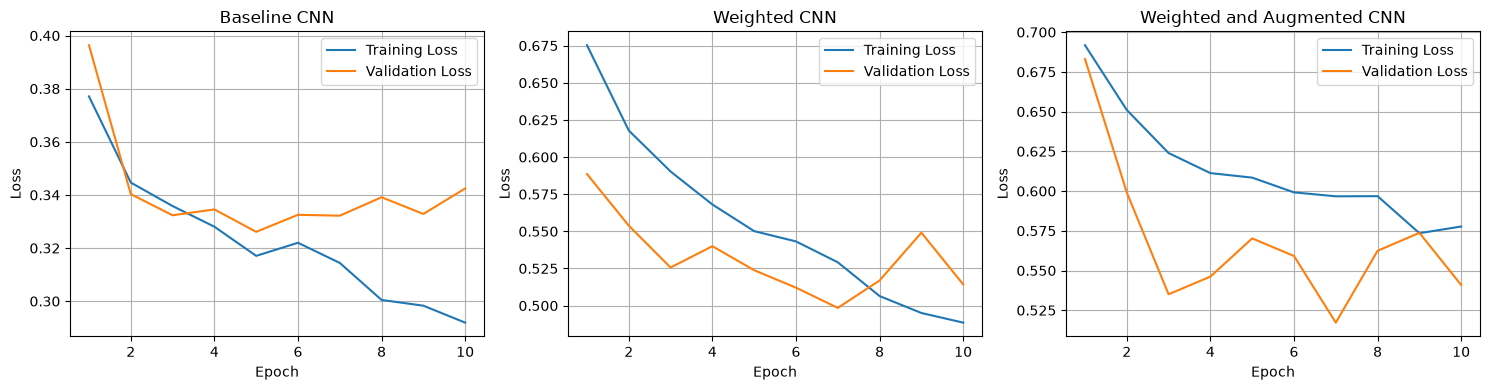

In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

epochs = range(1, 11)

# Baseline CNN
axes[0].plot(epochs, cnn_train_losses, label="Training Loss")
axes[0].plot(epochs, cnn_val_losses, label="Validation Loss")
axes[0].set_title("Baseline CNN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Weighted CNN
axes[1].plot(epochs, weighted_cnn_train_losses, label="Training Loss")
axes[1].plot(epochs, weighted_cnn_val_losses, label="Validation Loss")
axes[1].set_title("Weighted CNN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# Weighted and Augmented CNN
axes[2].plot(epochs, aug_train_losses, label="Training Loss")
axes[2].plot(epochs, aug_val_losses, label="Validation Loss")
axes[2].set_title("Weighted and Augmented CNN")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### 8.2 Validation metric comparison

|Validation metric	|Baseline CNN | Weighted CNN | Augmented & Weighted CNN|
| ------ | ----| -------| ------|
|Accuracy |86.64% |81.23% | 77.98% |
|Precision |37.50% | 36.36% | 32.69% |
|Recall |13.24% | 70.59% | 75.00% |
|F1	|19.57% | 48.00% | 45.54% |

Although the baseline CNN achieves the highest accuracy (86.64%), its recall is only 13.24%, indicating that it misses most Effusion cases.

The augmented and weighted CNN achieves the highest recall (75.00%), indicating that it detects the greatest proportion of actual Effusion cases. However, this comes at the cost of lower precision (32.69%) compared to the weighted CNN, suggesting that it produces more false positives. 

The weighted CNN performs best overall. Class weighting substantially improves recall from 13.24% to 70.59%, while maintaining the highest precision (36.36%) and F1 score (48.00%). This indicates that it achieves the best balance between precision and recall among the three models.

Therefore, we select the non-augmented weighted CNN model for further evaluation, as it offers the best balance between detecting Effusion cases and minimising false positives.

## 09. Final Evaluation of Weighted CNN on Held-Out Test Set

After comparing the three models, the weighted CNN was selected for final evaluation.

The held-out test dataset was not used during training or model selection. It is used here to assess how well the selected model generalises to unseen images. 

In [59]:
# Check whether the copied model matches the saved best weighted CNN weights

matches = all(
    torch.equal(
        model_param.cpu(),
        saved_param.cpu()
    )
    for model_param, saved_param in zip(
        weighted_cnn_model.state_dict().values(),
        weighted_best_model_state.values()
    )
)

print("Best weighted CNN epoch:", weighted_best_epoch)
print("Best validation loss:", weighted_best_val_loss)
print("Model weights match:", matches)

Best weighted CNN epoch: 7
Best validation loss: 0.4984859484765265
Model weights match: True


In [60]:
# Final evaluation on held-out test dataset
weighted_cnn_model.eval()
test_predictions = []
test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = weighted_cnn_model(images)
        predictions = torch.argmax(outputs, dim=1)
        test_predictions.extend(predictions.tolist())
        test_labels.extend(labels.tolist())

# Confusion matrix
cm_test = confusion_matrix(test_labels, test_predictions, labels=[0, 1])
print(f"Test Confusion Matrix: {cm_test}")

# Evaluation metrics
test_accuracy = accuracy_score(test_labels, test_predictions)
test_precision = precision_score(test_labels, test_predictions, zero_division=0)
test_recall = recall_score(test_labels, test_predictions, zero_division=0)
test_f1 = f1_score(test_labels, test_predictions, zero_division=0)
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1: {test_f1:.4f}")

Test Confusion Matrix: [[187 142]
 [ 48 102]]
Accuracy: 0.6033
Precision: 0.4180
Recall: 0.6800
F1: 0.5178


## 10. Discussion

### 10.1 Baseline CNN

The baseline CNN achieved an accuracy of 86.64%, but its performance in detecting effusion was poor. The model achieved only 13.24% recall and and F1-score of 19.57%, 
demonstrating how accuracy can be misleading when working with imbalanced datasets. Despite its relatively high accuracy, the model failed to identify most of the minority-class Effusion images.

### 10.2 Weighted CNN

To address class imbalance, a second CNN was trained using class-weighted cross-entropy loss, assigning a higher penalty to incorrect predictions of the minority Effusion class.

The weighted CNN achieved an accuracy of 81.23%, precision of 36.36%, recall of 70.59%, and F1-score of 48.00% on the validation set. 

Compared to the baseline, the weighted CNN substantially improved Effusion detection, increasing recall score from 13.24% to 70.59%. However, this came at the cost of lower precision, indicating a greater proportion of alse positives among its Effusion predictions. This experiment demonstrated the trade-off between precision and recall, and how class weighting can influence a model's classification behaviour. 

### 10.3 Augmented & Weighted CNN

To introduce some variation into training images and potentially improve generalisation, a third CNN was trained using image augmentation alongside class-weighted loss.

The augmented and weighted CNN achieved an accuracy of 77.98%, precision of 32.69%, recall of 75.00%, and F1-score of 45.54% on the validation set. 

Compared to the weighted CNN, the augmented and weighted CNN achieved a slightly higher recall score from 70.59% to 75.00%. However, this came at the cost of lower precision, which decreased from 36.36% to 32.69%. Consequently, its F1-score also decreased from 48.00% to 45.54%.

Although augmentation improved recall slightly, it did not improve the overall precision-recall balance in this experiement. Therefore, the non-augmented weighted CNN was selected for further evaluation.

### 10.4 Performance of Weighted CNN on test dataset

The weighted CNN was selected and evaluated on the held-out test dataset.

| Metric | Validation | Test |
| ------ | ---------- | ---- |
| Accuracy | 81.23% | 60.33% |
| Precision | 36.36% | 41.80% |
| Recall | 70.59% | 68.00% |
| F1 | 48.00% | 51.78% |

The recall score remained relatively stable: decreasing slightly from 70.59% on validation to 68.00% on test set, indicating that the model identified 68% of actual Effusion cases in the held-out test set. 

Precision increased from 36.36% to 41.80%, contributing to an increase in the F1-score from 48.00% to 51.78%. 

However, accuracy on the test set is dropped substantially, from 81.23% to 60.33%. One factor to consider is the difference in class distribution between validation and test datasets. The test dataset contained a higher proportion of Effusion images, which affects metrics such as accuracy and precision.

The test confusion matrix also showed that the model correctly identified 102 out of 150 Effusion cases, while incorrectly classifying 142 No Finding cases as Effusion, highlighting the model's continued difficult in distinguishing between the 2 classes.

### 10.5 Comparing Weighted CNN to Weighted MLP on test set

The weighted CNN model was compared against the weighted MLP model using the same held-out test dataset.

| Metric | Weighted CNN | Weighted MLP |
| ------ | ---------- | ---- |
| Accuracy | 60.33% | 51.77% |
| Precision | 41.80% | 37.84% |
| Recall | 68.00% | 84.00% |
| F1 | 51.78% | 52.17% |

The weighted CNN achieved higher accuracy (60.33% vs 51.77%) and precision (41.80% vs 37.84%) compared to the weighted MLP. However, the weighted MLP achieved higher recall (84.00% vs 68.00%), indicating that it identified a greater proportion of actual Effusion cases. Both models achieved similar F1-scores, with the weighted MLP scoring 52.17% and the weighted CNN scoring 51.78%.

The results suggest that the CNN did not demonstrate a clear improvement over the MLP in overall classification performance. Although convolutional laters allow the model to learn spatial features from images, this did not translate into a substantial improvement in the precision-recall balance in this experiment.

The weighted MLP achieved slightly better Effusion detection and F1-score, while the weighted CNN achieved higher accuracy and precision, highlighting that a more complex model architecture does not guarantee better performance, particularly when working with a limited dataset and low-resolution images. 

### 10.6 Limitations

The following limitations should be considered:
1. The dataset was imbalanced, with significantly fewer Effusion images than No Finding images. 
2. The images were sized to 64x64, losing image detail. This may limit the model's ability to identify subtle radiographic features associated with Effusion.
3. The model was trained and evaluated on a small subset of the NIH ChestX-ray14 dataset. Its performance may differ when applied to a larger and more diverse dataset.
4. The experiment focused on binary classification between Effusion and No Finding. It does not assess the model's ability to distinguish Effusion from other thoracic diagnoses.
5. Model has not been evaluated on an independent external dataset. Its generalisability remains unknown.

## 11.  Conclusion

This project provided practical experience in building and training a convolutional neural network (CNN) using native PyTorch, covering data preparation, model architecture, training and validation loops, and performance evaluation. 

The experiments demonstrated the limitations of relying on accuracy alone when evaluating imbalanced medical image datasets. They also highlighted how class weighting can improve minority-class detection-- a common challenge in medical imaging. Image augmentation was introduced as a technique to improve generalisability, although it did not improve the overall precision-recall balance in this experiment.

Finally, comparison with the weighted MLP showed that the more complex CNN architecture did not necessarily translate into better classification performance. Both models achieved similar F1-scores, with different trade-offs between precision and recall.

Overall, this project strengthen my understanding of practical deep learning workflows and importance of selecting appropriate evaluation metrics when developing models for medical image classification.